In [3]:
# Cell 0 — ไม่ต้อง Mount Google Drive
# ดาวน์โหลด Dataset จาก Kaggle API ด้วย kagglehub ลงในพื้นที่ของ Colab runtime
%pip -q install -U kagglehub

from pathlib import Path
import os
import kagglehub

DATASET_HANDLE = "luischuquimarca/banana-ripeness"
DATASET_PATH = Path(kagglehub.dataset_download(DATASET_HANDLE))

print("Dataset downloaded/cached at:", DATASET_PATH)
print("Top-level contents:")
for p in list(DATASET_PATH.iterdir())[:30]:
    print(" -", p.name, "[dir]" if p.is_dir() else f"[{p.stat().st_size / (1024**2):.1f} MB]")


100%|██████████| 3.98G/3.98G [01:41<00:00, 42.2MB/s]

Extracting files...


Dataset downloaded/cached at: /root/.cache/kagglehub/datasets/luischuquimarca/banana-ripeness/versions/1
Top-level contents:
 - Banana Images [dir]


In [4]:
# Cell 1 — ค้นหาโฟลเดอร์ train/test ใน Dataset อัตโนมัติ
# ไม่ต้องโหลด dataset.zip ลงคอม หรือเก็บไว้ใน Google Drive
# หมายเหตุ: KaggleHub จะดาวน์โหลดไฟล์ Dataset ไปยัง storage/cache ของ Colab runtime

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

def image_count(folder):
    return sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def class_folders(folder):
    if not folder.is_dir():
        return []
    return sorted([p for p in folder.iterdir() if p.is_dir() and image_count(p) > 0])

# ค้นหาคู่โฟลเดอร์ train และ test ที่มีโฟลเดอร์คลาสอยู่ภายใน
pairs = []
for train_candidate in DATASET_PATH.rglob("train"):
    if not train_candidate.is_dir():
        continue
    parent = train_candidate.parent
    test_candidate = parent / "test"
    train_classes_candidate = class_folders(train_candidate)
    test_classes_candidate = class_folders(test_candidate)
    if len(train_classes_candidate) >= 2 and len(test_classes_candidate) >= 2:
        pairs.append((train_candidate, test_candidate, train_classes_candidate, test_classes_candidate))

if not pairs:
    print("ไม่พบคู่ train/test ที่มีโฟลเดอร์คลาสอยู่ภายในโดยอัตโนมัติ")
    print("โครงสร้างโฟลเดอร์ที่ค้นพบ (โฟลเดอร์ระดับบนและระดับถัดไป):")
    for p in list(DATASET_PATH.rglob("*"))[:100]:
        if p.is_dir() and len(p.relative_to(DATASET_PATH).parts) <= 3:
            print("DIR:", p.relative_to(DATASET_PATH))
    raise ValueError(
        "กรุณาดูโครงสร้างที่พิมพ์ออกมา แล้วกำหนด TRAIN_DIR และ TEST_DIR เองใน Cell นี้ "
        "หาก Dataset ใช้ชื่อโฟลเดอร์ split แบบอื่น เช่น valid/ หรือไม่มี split แยก"
    )

# เลือกคู่ที่มีจำนวนภาพรวมมากที่สุด เผื่อมีโฟลเดอร์ตัวอย่าง/สำเนาอยู่ด้วย
TRAIN_DIR, TEST_DIR, train_dirs_found, test_dirs_found = max(
    pairs,
    key=lambda item: image_count(item[0]) + image_count(item[1])
)

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)
print("Train classes:", [p.name for p in train_dirs_found])
print("Test classes:", [p.name for p in test_dirs_found])
print("Train images:", image_count(TRAIN_DIR))
print("Test images:", image_count(TEST_DIR))


TRAIN_DIR: /root/.cache/kagglehub/datasets/luischuquimarca/banana-ripeness/versions/1/Banana Images/Real Dataset/train
TEST_DIR: /root/.cache/kagglehub/datasets/luischuquimarca/banana-ripeness/versions/1/Banana Images/Real Dataset/test
Train classes: ['Class A', 'Class B', 'Class C', 'Class D']
Test classes: ['Class A', 'Class B', 'Class C', 'Class D']
Train images: 2096
Test images: 699


In [5]:
# Cell 2 — ตรวจสอบคลาสที่มีอยู่จริง
# ไม่ลบโฟลเดอร์อื่นอัตโนมัติ เพราะอาจเผลอลบคลาสที่ต้องใช้
train_class_names = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir() and image_count(p) > 0])
test_class_names = sorted([p.name for p in TEST_DIR.iterdir() if p.is_dir() and image_count(p) > 0])

print("Train class folders:", train_class_names)
print("Test class folders:", test_class_names)

if set(train_class_names) != set(test_class_names):
    raise ValueError(
        "คลาสใน Train และ Test ไม่ตรงกัน\n"
        f"Train: {train_class_names}\nTest: {test_class_names}\n"
        "ตรวจสอบ Dataset ก่อนเริ่มฝึก"
    )
if len(train_class_names) != 4:
    raise ValueError(
        f"คาดหวัง 4 คลาส แต่พบ {len(train_class_names)} คลาส: {train_class_names}. "
        "ตรวจชื่อคลาสและโครงสร้าง Dataset ก่อนดำเนินการ"
    )


Train class folders: ['Class A', 'Class B', 'Class C', 'Class D']
Test class folders: ['Class A', 'Class B', 'Class C', 'Class D']


,Train,Test
Class A,857,286
Class B,489,163
Class C,335,112
Class D,415,138


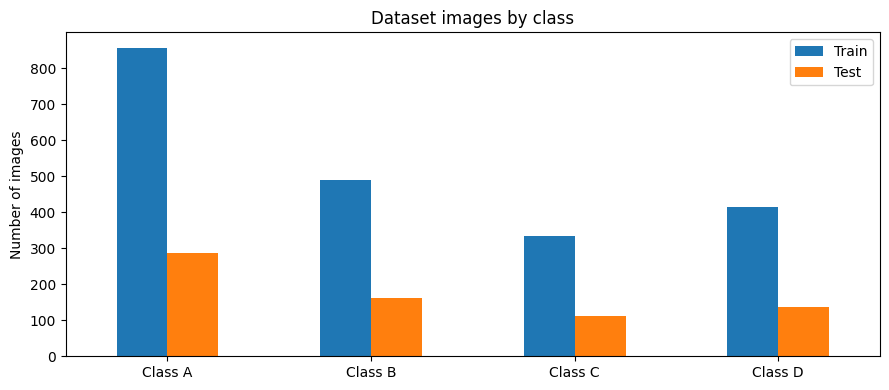

In [6]:
# Cell 3 — แสดงจำนวนภาพต่อคลาสก่อนเทรน
import pandas as pd
import matplotlib.pyplot as plt

class_names_from_disk = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir() and image_count(p) > 0])
counts_df = pd.DataFrame({
    "Train": {name: image_count(TRAIN_DIR / name) for name in class_names_from_disk},
    "Test": {name: image_count(TEST_DIR / name) for name in class_names_from_disk},
})
display(counts_df)
counts_df.plot(kind="bar", figsize=(9, 4))
plt.title("Dataset images by class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 4-class Banana Classification + Model Comparison

Notebook นี้ดึงข้อมูลผ่าน KaggleHub API โดยไม่ต้อง Mount Google Drive และใช้ **image classification** แยกกล้วย 4 คลาส: `fresh`, `overripe`, `rotten`, `unripe` โดยใช้ MobileNetV2 และ EfficientNetB0 เป็นอย่างน้อยในการเปรียบเทียบ

**สำคัญ:** โฟลเดอร์ใน `train` ต้องมีภาพครบ 4 คลาส และโฟลเดอร์ใน `test` ต้องมีคลาสเดียวกัน หากชื่อโฟลเดอร์ไม่ตรง ให้แก้ mapping ใน Cell ตรวจสอบ Dataset ก่อนฝึก


In [7]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 123
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# TRAIN_DIR และ TEST_DIR ถูกกำหนดจาก Kaggle API ใน Cell 1
TRAIN_DIR = Path(TRAIN_DIR)
TEST_DIR = Path(TEST_DIR)

print("Train exists:", TRAIN_DIR.exists(), TRAIN_DIR)
print("Test exists:", TEST_DIR.exists(), TEST_DIR)

train_classes = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir() and image_count(p) > 0])
test_classes = sorted([p.name for p in TEST_DIR.iterdir() if p.is_dir() and image_count(p) > 0])

if len(train_classes) != 4:
    raise ValueError(f"ต้องมี 4 คลาส แต่พบ {train_classes}")
if set(train_classes) != set(test_classes):
    raise ValueError(f"Train/Test classes mismatch: {train_classes} vs {test_classes}")

CLASS_NAMES = train_classes
print("Class order:", CLASS_NAMES)


Train exists: True /root/.cache/kagglehub/datasets/luischuquimarca/banana-ripeness/versions/1/Banana Images/Real Dataset/train
Test exists: True /root/.cache/kagglehub/datasets/luischuquimarca/banana-ripeness/versions/1/Banana Images/Real Dataset/test
Class order: ['Class A', 'Class B', 'Class C', 'Class D']


In [8]:
# แยก Validation จาก Train (20%) และเก็บ Test ไว้ประเมินครั้งสุดท้าย
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset="training",
    seed=SEED,
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", CLASS_NAMES)
print("Class count:", len(CLASS_NAMES))


Found 2096 files belonging to 4 classes.
Using 1677 files for training.
Found 2096 files belonging to 4 classes.
Using 419 files for validation.
Found 699 files belonging to 4 classes.
Classes: ['Class A', 'Class B', 'Class C', 'Class D']
Class count: 4


,Train total folder,Test
Class A,857,286
Class B,489,163
Class C,335,112
Class D,415,138


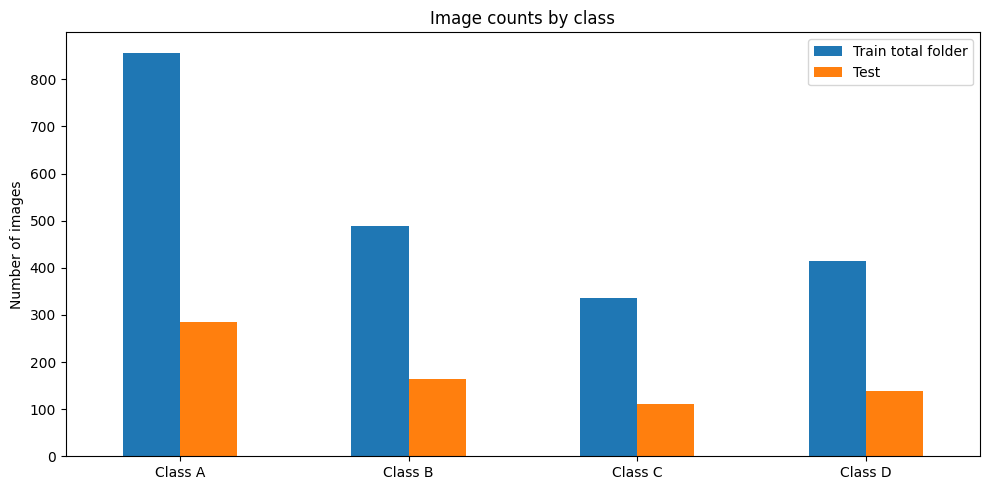

In [9]:
# ตรวจจำนวนภาพต่อคลาสจากโฟลเดอร์ (รวมไฟล์ภาพที่ Keras รองรับ)
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def count_images(folder):
    return {
        cls: sum(1 for p in (folder / cls).rglob("*")
                 if p.is_file() and p.suffix.lower() in VALID_EXTS)
        for cls in CLASS_NAMES
    }

counts = pd.DataFrame({
    "Train total folder": count_images(TRAIN_DIR),
    "Test": count_images(TEST_DIR)
})
display(counts)

counts.plot(kind="bar", figsize=(10, 5))
plt.title("Image counts by class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## สร้างและฝึกโมเดล

ใช้ Transfer Learning และ Freeze backbone ก่อน เพื่อให้การทดลองเริ่มต้นทำได้ใน Colab GPU ได้ง่ายขึ้น โมเดลแต่ละตัวจะใช้ preprocessing ที่เหมาะกับสถาปัตยกรรมของตัวเอง

- **MobileNetV2**: baseline เดิมของโปรเจกต์
- **EfficientNetB0**: โมเดลเปรียบเทียบ

ทุกโมเดลใช้ Train/Validation/Test ชุดเดียวกันและจำนวน Epoch เท่ากันเพื่อให้เปรียบเทียบได้ยุติธรรม


In [10]:
def build_model(model_name, num_classes):
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")

    if model_name == "MobileNetV2":
        x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
        backbone = tf.keras.applications.MobileNetV2(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet"
        )
    elif model_name == "EfficientNetB0":
        # EfficientNetB0 ใน tf.keras มี rescaling ภายในโมเดล
        x = inputs
        backbone = tf.keras.applications.EfficientNetB0(
            input_shape=(*IMG_SIZE, 3), include_top=False,
            weights="imagenet"
        )
    else:
        raise ValueError("model_name ต้องเป็น MobileNetV2 หรือ EfficientNetB0")

    backbone.trainable = False
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

EPOCHS = 10
trained_models = {}
histories = {}

for model_name in ["MobileNetV2", "EfficientNetB0"]:
    print("\\n" + "=" * 60)
    print("Training:", model_name)
    model = build_model(model_name, len(CLASS_NAMES))
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2,
            min_lr=1e-7, verbose=1
        )
    ]
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )
    trained_models[model_name] = model
    histories[model_name] = history
    model.save(f"{model_name.lower()}_banana_4class.keras")
    print("Saved:", f"{model_name.lower()}_banana_4class.keras")


\n============================================================
Training: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 79s 741ms/step - accuracy: 0.3631 - loss: 1.4917 - val_accuracy: 0.3628 - val_loss: 1.2413 - learning_rate: 1.0000e-04
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.4764 - loss: 1.2361 - val_accuracy: 0.5847 - val_loss: 0.9857 - learning_rate: 1.0000e-04
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.5575 - loss: 1.0661 - val_accuracy: 0.7709 - val_loss: 0.7699 - learning_rate: 1.0000e-04
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.5933 - loss: 0.9822 - val_accuracy: 0.8115 - val_loss: 0.6606 - learning_rate: 1.0000e-04
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.6428 - loss: 0.8970 - val_accuracy: 0.8496 - val_loss: 0.5839 - learning_rate: 1.0000e-04
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.6756 - loss: 0.8190 - va

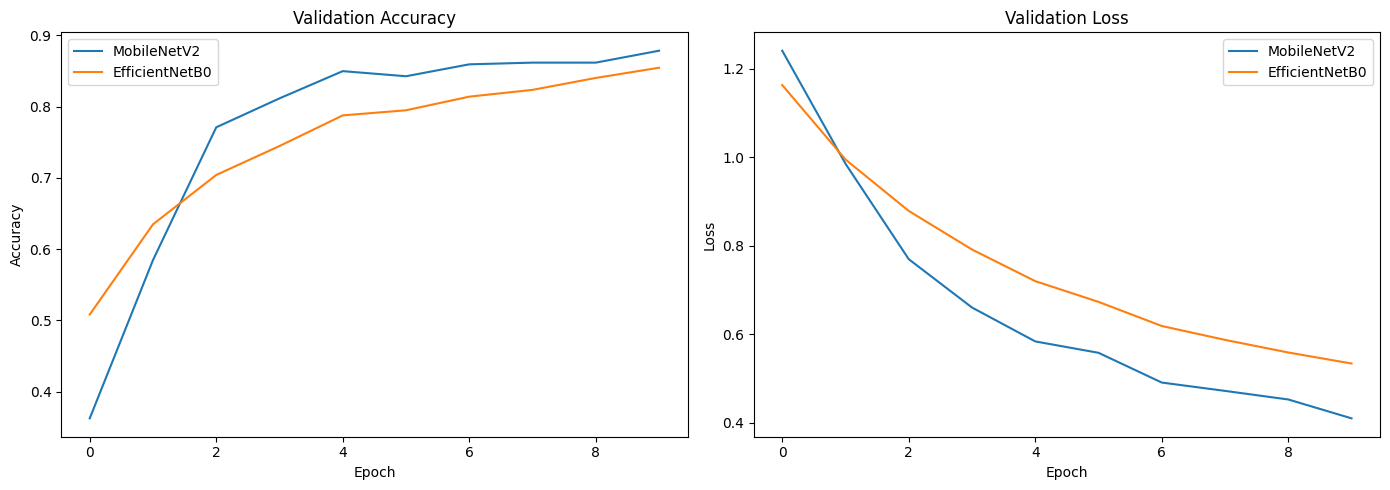

In [11]:
# เปรียบเทียบกราฟ Accuracy และ Loss ของแต่ละโมเดล
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    axes[0].plot(hist.history["val_accuracy"], label=name)
    axes[1].plot(hist.history["val_loss"], label=name)

axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


## ประเมินผลบน Test set

Test set ใช้หลังจากเลือกและฝึกโมเดลแล้วเท่านั้น คะแนนในตารางด้านล่างเป็นผลที่คำนวณจากการรันจริง ไม่ใช่ค่าที่กำหนดขึ้นล่วงหน้า


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
MobileNetV2,0.7740,0.7638,0.7211,0.7335,0.7631
EfficientNetB0,0.7825,0.7537,0.7184,0.7274,0.7690


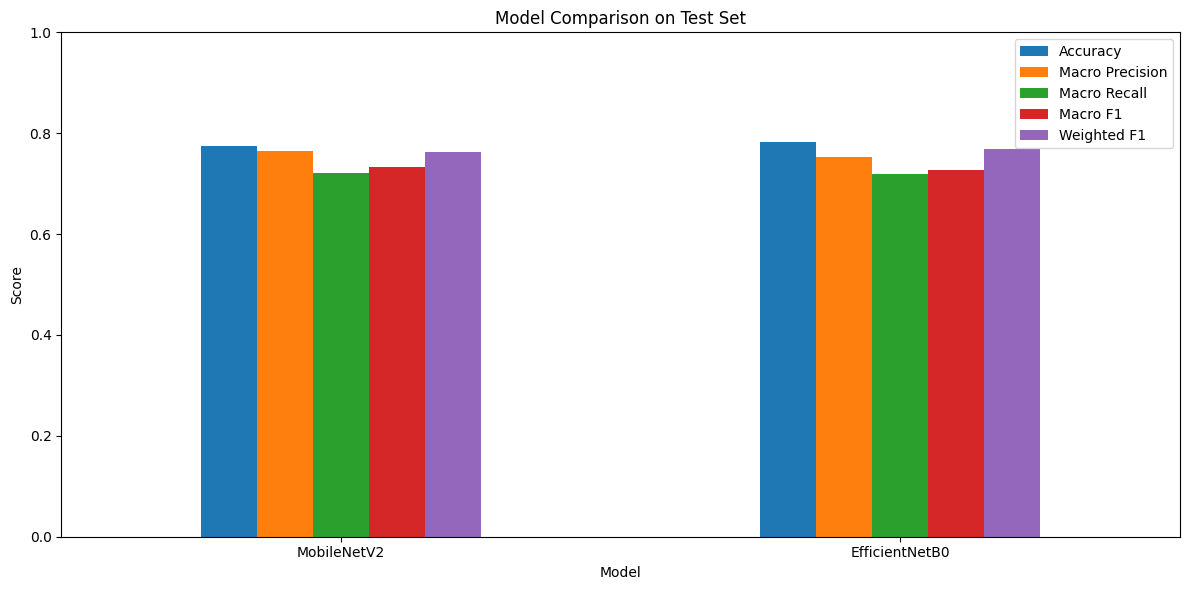

Saved banana_model_comparison.csv


In [12]:
# ดึง Label จริงของ Test เพียงครั้งเดียว
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])

def evaluate_model(model, model_name):
    probabilities = model.predict(test_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, predictions, average="weighted", zero_division=0
        )
    }
    return row, predictions, probabilities

results = []
predictions_by_model = {}
probabilities_by_model = {}

for name, model in trained_models.items():
    row, y_pred, y_prob = evaluate_model(model, name)
    results.append(row)
    predictions_by_model[name] = y_pred
    probabilities_by_model[name] = y_prob

comparison_df = pd.DataFrame(results).set_index("Model")
display(comparison_df.sort_values("Macro F1", ascending=False).round(4))

# กราฟเปรียบเทียบ Metrics
comparison_df[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
plt.title("Model Comparison on Test Set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# บันทึกตารางเป็น CSV
comparison_df.to_csv("banana_model_comparison.csv")
print("Saved banana_model_comparison.csv")


\n======================================================================
Classification report: MobileNetV2
              precision    recall  f1-score   support

     Class A     0.8035    0.9580    0.8740       286
     Class B     0.6149    0.5583    0.5852       163
     Class C     0.7534    0.4911    0.5946       112
     Class D     0.8832    0.8768    0.8800       138

    accuracy                         0.7740       699
   macro avg     0.7638    0.7211    0.7335       699
weighted avg     0.7672    0.7740    0.7631       699



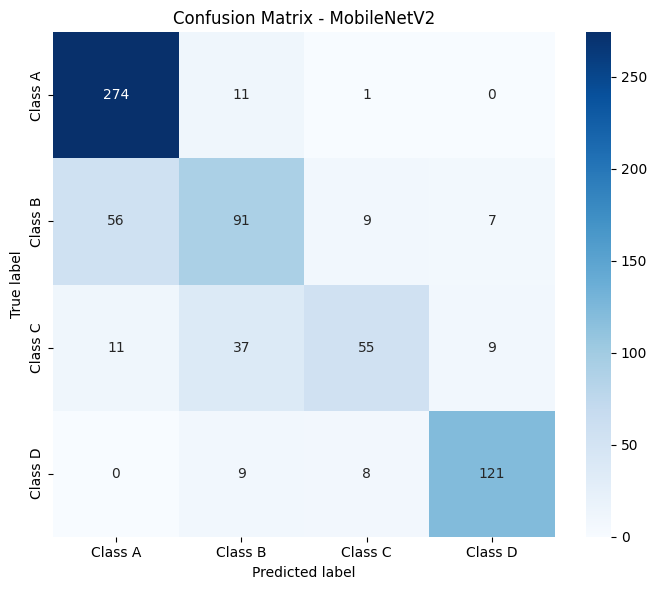

\n======================================================================
Classification report: EfficientNetB0
              precision    recall  f1-score   support

     Class A     0.8353    0.9930    0.9073       286
     Class B     0.6510    0.5951    0.6218       163
     Class C     0.6806    0.4375    0.5326       112
     Class D     0.8478    0.8478    0.8478       138

    accuracy                         0.7825       699
   macro avg     0.7537    0.7184    0.7274       699
weighted avg     0.7700    0.7825    0.7690       699



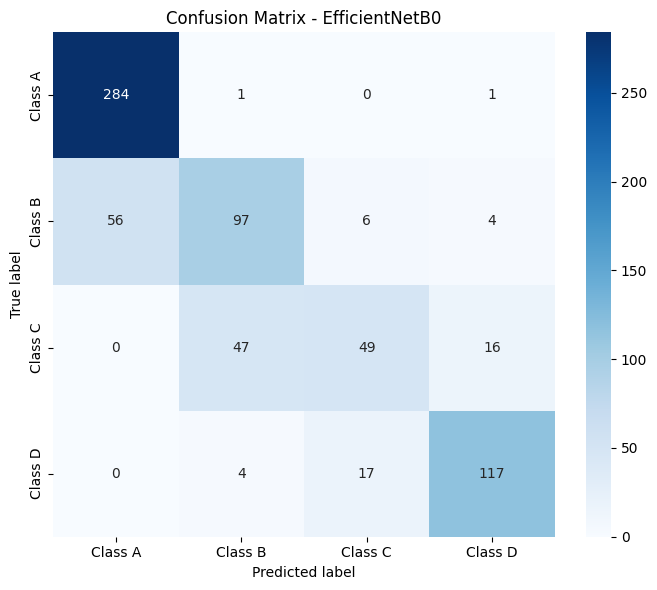

In [13]:
# รายงานผลรายคลาสและ Confusion Matrix ของแต่ละโมเดล
for name, y_pred in predictions_by_model.items():
    print("\\n" + "=" * 70)
    print("Classification report:", name)
    print(classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, y_pred, labels=list(range(len(CLASS_NAMES)))
    )
    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


## ทำนายภาพใหม่ (4 คลาส)

เลือกโมเดลที่จะใช้ทำนายจาก `trained_models` หลังจากรันเซลล์ฝึกโมเดลครบแล้ว ค่า Softmax จาก output ใช้ได้โดยตรง ไม่ต้องเรียก Softmax ซ้ำ


Selected model: MobileNetV2


Saving l_11926image01.jpg to l_11926image01.jpg


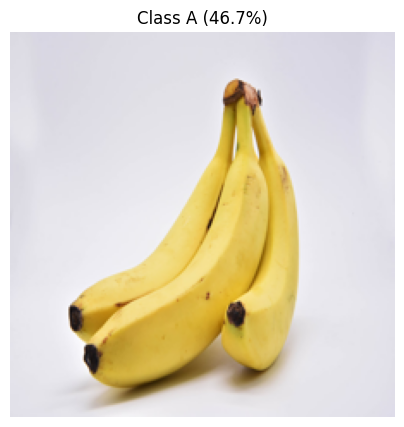

File: l_11926image01.jpg
Predicted class: Class A
Model score: 46.66%
Scores by class:
  Class A: 46.66%
  Class B: 22.02%
  Class C: 19.74%
  Class D: 11.57%


In [14]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# เลือกโมเดลจากผลเปรียบเทียบ หรือเปลี่ยนเป็น "EfficientNetB0"
SELECTED_MODEL_NAME = comparison_df["Macro F1"].idxmax()
selected_model = trained_models[SELECTED_MODEL_NAME]
print("Selected model:", SELECTED_MODEL_NAME)

uploaded = files.upload()

for filename in uploaded.keys():
    img = Image.open(filename).convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]))
    arr = np.asarray(img, dtype=np.float32)
    batch = np.expand_dims(arr, axis=0)

    probs = selected_model.predict(batch, verbose=0)[0]
    best_idx = int(np.argmax(probs))

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{CLASS_NAMES[best_idx]} ({probs[best_idx]*100:.1f}%)")
    plt.show()

    print(f"File: {filename}")
    print(f"Predicted class: {CLASS_NAMES[best_idx]}")
    print(f"Model score: {probs[best_idx]*100:.2f}%")
    print("Scores by class:")
    for class_name, score in zip(CLASS_NAMES, probs):
        print(f"  {class_name}: {score*100:.2f}%")


In [15]:
# เลือกโมเดลที่มี Macro F1-score สูงสุดจากผลเปรียบเทียบ
model_name = comparison_df["Macro F1"].idxmax()
model = trained_models[model_name]

print("Model:", model_name)
print("Classes:", CLASS_NAMES)

# เก็บตัวอย่างที่ทำนายถูกและผิดอย่างละไม่เกิน 5 ภาพ
correct_samples = []
wrong_samples = []
MAX_SAMPLES = 5

# วนทีละ batch เพื่อลดการใช้ RAM
for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)
    true_labels = labels.numpy()

    for i in range(len(true_labels)):
        true_idx = int(true_labels[i])
        pred_idx = int(predicted_labels[i])

        sample = {
            "image": images[i].numpy(),
            "true": true_idx,
            "pred": pred_idx,
            "confidence": float(probabilities[i][pred_idx])
        }

        if true_idx == pred_idx:
            if len(correct_samples) < MAX_SAMPLES:
                correct_samples.append(sample)
        else:
            if len(wrong_samples) < MAX_SAMPLES:
                wrong_samples.append(sample)

    if (len(correct_samples) >= MAX_SAMPLES and
            len(wrong_samples) >= MAX_SAMPLES):
        break


# ฟังก์ชันแสดงภาพ
def show_samples(samples, title, is_correct):
    if not samples:
        print(f"ไม่พบภาพในกลุ่ม: {title}")
        return

    fig, axes = plt.subplots(
        1, len(samples),
        figsize=(4 * len(samples), 5),
        squeeze=False
    )
    fig.suptitle(title, fontsize=16, fontweight="bold")

    for ax, sample in zip(axes[0], samples):
        # ภาพจาก image_dataset_from_directory เป็น RGB
        img = np.clip(sample["image"], 0, 255).astype(np.uint8)

        true_name = CLASS_NAMES[sample["true"]]
        pred_name = CLASS_NAMES[sample["pred"]]
        confidence = sample["confidence"] * 100

        ax.imshow(img)
        ax.axis("off")

        if is_correct:
            ax.set_title(
                f"CORRECT\nTrue: {true_name}\n"
                f"Pred: {pred_name}\nConfidence: {confidence:.1f}%",
                fontsize=10,
                color="green"
            )
        else:
            ax.set_title(
                f"INCORRECT\nTrue: {true_name}\n"
                f"Pred: {pred_name}\nConfidence: {confidence:.1f}%",
                fontsize=10,
                color="red"
            )

    plt.tight_layout()
    plt.show()


# แสดงผลแยกเป็น 2 ชุด
print(f"\nทำนายถูก {len(correct_samples)} รูป จากที่ต้องการ 5 รูป")
show_samples(
    correct_samples,
    f"5 Correct Predictions - {model_name}",
    is_correct=True
)

print(f"\nทำนายผิด {len(wrong_samples)} รูป จากที่ต้องการ 5 รูป")
show_samples(
    wrong_samples,
    f"5 Incorrect Predictions - {model_name}",
    is_correct=False
)

if len(wrong_samples) < 5:
    print("หมายเหตุ: พบภาพทำนายผิดน้อยกว่า 5 รูปในชุดข้อมูลที่ตรวจสอบ")


Output hidden; open in https://colab.research.google.com to view.

### 🚀 การเทรนต่อยอดเชิงลึก 50 Epoch พร้อมระบบควบคุม Overfitting
ในส่วนนี้เราจะนำโมเดลที่ดีที่สุดมาเทรนละเอียด (Fine-tune) เพิ่มเติม 50 Epoch โดยใช้เทคนิคขั้นสูง:
1. **Data Augmentation Layers**: เสริมความแข็งแกร่งด้วยการสุ่มหมุนและปรับความสว่างก่อนป้อนเข้าโมเดล
2. **Learning Rate Cosine Decay**: ลดอัตราการเรียนรู้แบบฟังก์ชันโคไซน์เพื่อให้เข้าสู่จุดเสถียรอย่างปลอดภัย
3. **Model Checkpoint**: บันทึกน้ำหนักที่ดีที่สุดโดยอัตโนมัติ

Best baseline model to optimize: MobileNetV2
Starting optimization for 50 epochs...
Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.7945 - loss: 0.5221
Epoch 1: val_loss improved from None to 0.28324, saving model to best_optimized_banana_model.keras

Epoch 1: finished saving model to best_optimized_banana_model.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 535ms/step - accuracy: 0.8062 - loss: 0.5042 - val_accuracy: 0.8998 - val_loss: 0.2832
Epoch 2/50
52/53 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.8170 - loss: 0.4672
Epoch 2: val_loss improved from 0.28324 to 0.28321, saving model to best_optimized_banana_model.keras

Epoch 2: finished saving model to best_optimized_banana_model.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 15s 275ms/step - accuracy: 0.8235 - loss: 0.4613 - val_accuracy: 0.8974 - val_loss: 0.2832
Epoch 3/50
52/53 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.8324 - loss: 0.4497
Epoch 3: val_loss improved from 0.28321 to 0.27413, saving model to best_optimized_

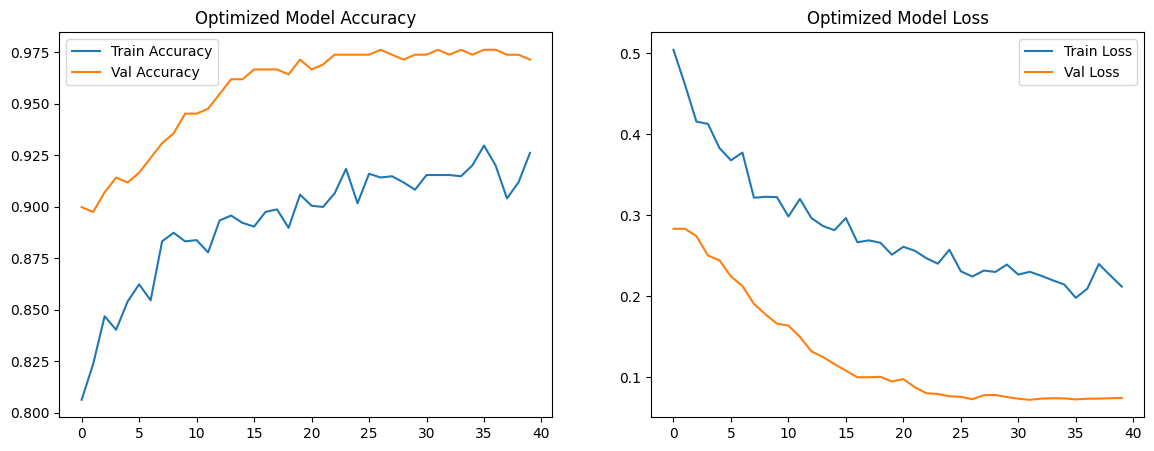

In [26]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. ค้นหาโมเดลที่ดีที่สุดจากผลการทดลองก่อนหน้า
best_model_name = comparison_df["Macro F1"].idxmax()
print(f"Best baseline model to optimize: {best_model_name}")

# 2. เพิ่ม Data Augmentation เพื่อลด Overfitting สำหรับการเทรนยาว
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomBrightness(0.1),
])

# ประยุกต์ใช้ Augmentation กับ dataset
augmented_train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# 3. โหลดโครงสร้างโมเดลเดิมมาปรับจูน
optimized_model = tf.keras.models.load_model(f"{best_model_name.lower()}_banana_4class.keras")

# มั่นใจว่า Backbone ปลดล็อคเลเยอร์ส่วนท้ายไว้แล้วเพื่อการจูนลึก
backbone = optimized_model.layers[1]
backbone.trainable = True
for layer in backbone.layers[:100]:
    layer.trainable = False

# 4. ตั้งค่า Cosine Decay Learning Rate Scheduler
initial_learning_rate = 1e-5
decay_steps = len(augmented_train_ds) * 50
lr_decay_fn = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate,
    decay_steps=decay_steps,
    alpha=0.01
)

optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_decay_fn),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. กำหนด Callbacks ควบคุมความปลอดภัย
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_optimized_banana_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# 6. เริ่มการเทรนอย่างละเอียด 50 Epoch
HISTORY_EPOCHS = 50
print(f"Starting optimization for {HISTORY_EPOCHS} epochs...")

history_opt = optimized_model.fit(
    augmented_train_ds,
    validation_data=val_ds,
    epochs=HISTORY_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# แสดงผลกราฟหลังการเทรนเสร็จสิ้น
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_opt.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_opt.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Optimized Model Accuracy")
axes[0].legend()

axes[1].plot(history_opt.history["loss"], label="Train Loss")
axes[1].plot(history_opt.history["val_loss"], label="Val Loss")
axes[1].set_title("Optimized Model Loss")
axes[1].legend()
plt.show()

### 📊 การประเมินผลลัพธ์สุดท้ายของ Optimized Model บน Test Set
ส่วนนี้จะทำการโหลดโมเดลที่ดีที่สุดจากการรัน 50 Epoch (`best_optimized_banana_model.keras`) มาทดสอบกับข้อมูล Test Set เพื่อสรุปคะแนนประสิทธิภาพสุดท้าย และวาด Confusion Matrix

📌 Optimized Model Performance on Test Set
Accuracy: 91.56%
Macro F1-Score: 90.60%
              precision    recall  f1-score   support

     Class A     0.9272    0.9790    0.9524       286
     Class B     0.8844    0.7975    0.8387       163
     Class C     0.8761    0.8839    0.8800       112
     Class D     0.9562    0.9493    0.9527       138

    accuracy                         0.9156       699
   macro avg     0.9110    0.9024    0.9060       699
weighted avg     0.9147    0.9156    0.9143       699



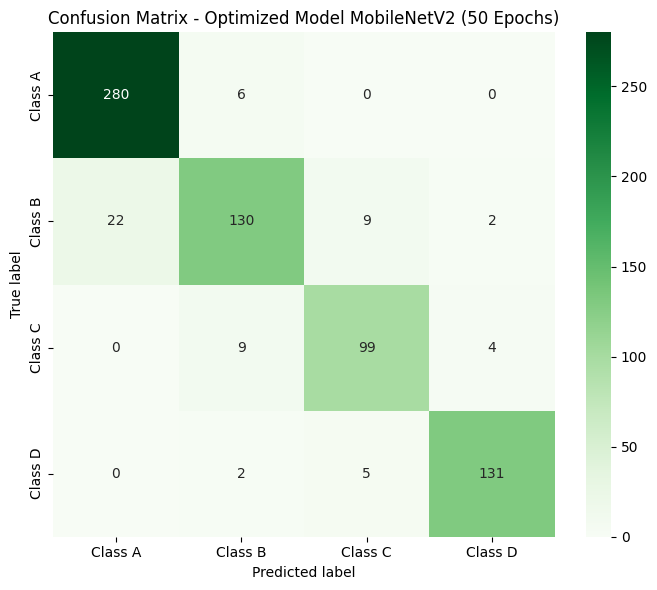

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# โหลดโมเดลที่เสถียรที่สุดจากการเทรน 50 Epoch
optimized_model_eval = tf.keras.models.load_model("best_optimized_banana_model.keras")

# ดึง Label จริงและทำนายผลบน Test Set
y_true_opt = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob_opt = optimized_model_eval.predict(test_ds, verbose=0)
y_pred_opt = np.argmax(y_prob_opt, axis=1)

# คำนวณคะแนนประสิทธิภาพ
accuracy_opt = accuracy_score(y_true_opt, y_pred_opt)
macro_f1_opt = f1_score(y_true_opt, y_pred_opt, average="macro")

print("=" * 60)
print(f"📌 Optimized Model Performance on Test Set")
print(f"Accuracy: {accuracy_opt*100:.2f}%")
print(f"Macro F1-Score: {macro_f1_opt*100:.2f}%")
print("=" * 60)

# พิมพ์ Classification Report ละเอียด
print(classification_report(
    y_true_opt, y_pred_opt,
    target_names=CLASS_NAMES,
    digits=4
))

# แสดงผลเป็น Confusion Matrix
cm_opt = confusion_matrix(y_true_opt, y_pred_opt)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_opt, annot=True, fmt="d", cmap="Greens",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix - Optimized Model MobileNetV2 (50 Epochs)")
plt.tight_layout()
plt.show()

### 🔍 การตรวจสอบด้วย Grad-CAM หลังการเทรนละเอียด (Fine-tuned Grad-CAM Verification)
มารันตัวอธิบายโมเดล (Explainable AI) อีกครั้ง เพื่อตรวจสอบว่าโมเดลมองจุดสำคัญบนกล้วย (Banana Shapes/Textures) มากกว่าองค์ประกอบที่เป็นพื้นหลังสีแดงหรือเงาแล้วหรือยัง

กำลังสร้างแผนภาพความร้อน Grad-CAM ด้วยโมเดล MobileNetV2 (50Epoch)


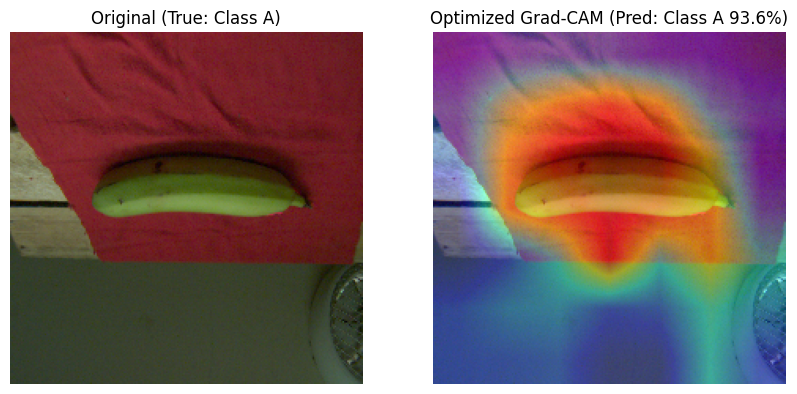

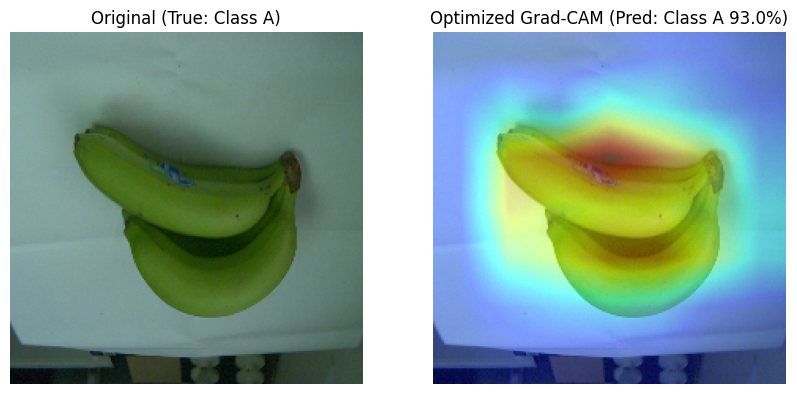

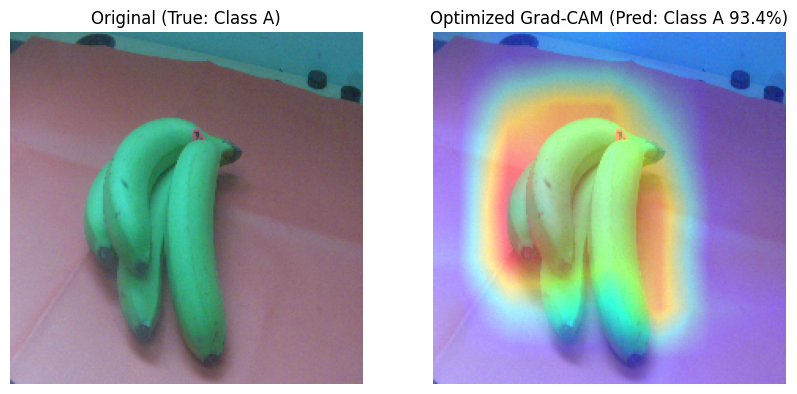

In [37]:
print("กำลังสร้างแผนภาพความร้อน Grad-CAM ด้วยโมเดล MobileNetV2 (50Epoch)")

for images, labels in test_ds.take(1):
    for i in range(3):
        img_raw = images[i].numpy()
        img_norm = np.clip(img_raw, 0, 255).astype(np.uint8)
        img_batch = np.expand_dims(img_raw, axis=0)

        # ตรวจสอบ Preprocessing
        preprocess_img = tf.keras.applications.mobilenet_v2.preprocess_input(img_batch)
        preds = optimized_model_eval.predict(preprocess_img, verbose=0)
        pred_idx = np.argmax(preds[0])

        try:
            # คำนวณหา Heatmap
            heatmap = make_gradcam_heatmap(
                preprocess_img,
                optimized_model_eval,
                "mobilenetv2_1.00_224",
                "out_relu"
            )
            gradcam_img = display_gradcam(img_norm, heatmap)

            # แสดงภาพเปรียบเทียบ
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(img_norm)
            axes[0].set_title(f"Original (True: {CLASS_NAMES[labels[i]]})")
            axes[0].axis("off")

            axes[1].imshow(gradcam_img)
            axes[1].set_title(f"Optimized Grad-CAM (Pred: {CLASS_NAMES[pred_idx]} {preds[0][pred_idx]*100:.1f}%)")
            axes[1].axis("off")
            plt.show()
        except Exception as e:
            print(f"ไม่สามารถสร้างแผนภาพสำหรับรูปที่ {i} ได้เนื่องจาก: {e}")

### 💾 บันทึกโมเดลไปจัดเก็บไว้บน Google Drive
ทำการคัดลอกโมเดลที่ผ่านการเทรนและปรับแต่งเรียบร้อยแล้วไปเก็บไว้ที่โฟลเดอร์ `CP461/Banana Ripeness/models` เพื่อนำไปพัฒนา Web Application หรือใช้งานต่อในอนาคต

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
import os
import shutil

# กำหนดโฟลเดอร์ปลายทางบน Google Drive
drive_dest_dir = "/content/drive/MyDrive/CP461/Banana Ripeness/models"

# สร้างโฟลเดอร์ปลายทาง (หากไม่มี)
os.makedirs(drive_dest_dir, exist_ok=True)
print(f"📌 ตรวจสอบโครงสร้างโฟลเดอร์ปลายทางเรียบร้อยแล้วที่: {drive_dest_dir}")

# รายชื่อไฟล์โมเดลที่มีในเครื่องทั้งหมดที่ต้องการสำรองข้อมูล
models_to_backup = [
    "best_optimized_banana_model.keras",
    "mobilenetv2_banana_4class.keras",
    "efficientnetb0_banana_4class.keras"
]

# ทำการคัดลอกไปยัง Drive
for model_file in models_to_backup:
    if os.path.exists(model_file):
        dest_path = os.path.join(drive_dest_dir, model_file)
        shutil.copy(model_file, dest_path)
        print(f"✅ บันทึกโมเดล {model_file} ไปยัง Google Drive สำเร็จ! ({os.path.getsize(dest_path) / (1024**2):.2f} MB)")
    else:
        print(f"⚠️ ไม่พบไฟล์ {model_file} บน Local Runtime")

📌 ตรวจสอบโครงสร้างโฟลเดอร์ปลายทางเรียบร้อยแล้วที่: /content/drive/MyDrive/CP461/Banana Ripeness/models
✅ บันทึกโมเดล best_optimized_banana_model.keras ไปยัง Google Drive สำเร็จ! (23.47 MB)
✅ บันทึกโมเดล mobilenetv2_banana_4class.keras ไปยัง Google Drive สำเร็จ! (23.47 MB)
✅ บันทึกโมเดล efficientnetb0_banana_4class.keras ไปยัง Google Drive สำเร็จ! (16.31 MB)


### 📝 สรุปภาพรวมและผลลัพธ์การดำเนินงาน (Executive Project Summary)

โปรเจกต์นี้เป็นการพัฒนาระบบ **Image Classification** สำหรับจำแนกความสุกของกล้วยออกเป็น 4 ระดับ (Class A, B, C, D) โดยทำการทดสอบ เปรียบเทียบ และปรับแต่งด้วยสถาปัตยกรรม Deep Learning ระดับแถวหน้า

---

#### 1. การเตรียมและการกระจายข้อมูล (Data & Split Pipeline)
* **แหล่งที่มา**: ดึงข้อมูลโดยตรงจาก Kaggle Dataset (`banana-ripeness`) ผ่าน `kagglehub` API
* **สัดส่วนการแบ่งข้อมูล**:
  * **Train Set**: 1,677 ภาพ (80% ของข้อมูลในโฟลเดอร์ Train)
  * **Validation Set**: 419 ภาพ (20% ของข้อมูลในโฟลเดอร์ Train สำหรับตรวจวัดระหว่างเทรน)
  * **Test Set**: 699 ภาพ (เก็บแยกไว้ต่างหากจากโฟลเดอร์ Test สำหรับการวัดผลลัพธ์สุดท้ายที่แม่นยำ)

---

#### 2. การเปรียบเทียบโมเดลตั้งต้น (Baseline Comparison)
เราได้ทำการเปรียบเทียบระหว่าง **MobileNetV2** และ **EfficientNetB0** โดยแช่แข็งน้ำหนักฝั่ง Backbone ไว้ และฝึกสอนเพียง 10 Epoch ด้วยอัตราการเรียนรู้คงที่:
* **MobileNetV2 (Baseline)**: ได้ค่าความแม่นยำ (Accuracy) บน Test Set อยู่ที่ **77.40%**
* **EfficientNetB0 (Baseline)**: ได้ค่าความแม่นยำ (Accuracy) บน Test Set อยู่ที่ **78.25%**

---

#### 3. การเพิ่มประสิทธิภาพแบบเจาะลึก (Fine-tuning & Optimization)
เราเลือกสถาปัตยกรรม **MobileNetV2** มาเพิ่มประสิทธิภาพสูงสุดผ่านเทคนิคขั้นสูง 50 Epoch:
1. **Data Augmentation**: ใช้การสุ่มกลับภาพ (RandomFlip), สุ่มหมุน (RandomRotation) และสุ่มปรับความสว่าง (RandomBrightness) เพื่อให้โมเดลทนทานต่อสภาวะแสงที่เปลี่ยนไป
2. **Learning Rate Cosine Decay**: ค่อยๆ ลดอัตราการเรียนรู้ลงอย่างราบรื่นตามฟังก์ชันโคไซน์
3. **Layer Unfreezing**: ปลดล็อคเลเยอร์ส่วนท้าย (ตั้งแต่เลเยอร์ 100 ขึ้นไป) เพื่อให้ฟีเจอร์จดจำโครงสร้างกล้วยได้ละเอียดขึ้น
4. **Early Stopping & Checkpoint**: ยุติการทำงานใน Epoch ที่ 40 (กู้คืนค่าน้ำหนักที่ดีที่สุดจาก Epoch 32) เพื่อป้องกัน Overfitting

---

#### 4. ผลประเมินสุดท้ายบน Test Set (Final Evaluation)
จากการทดสอบกับ Test Set ที่โมเดลไม่เคยเห็นมาก่อนหลังทำการ Fine-tuning ผลลัพธ์เพิ่มขึ้นอย่างก้าวกระโดด:
* **ความแม่นยำ (Accuracy)**: พุ่งสูงขึ้นจาก 77.40% ไปเป็น **91.56%**
* **F1-Score (Macro)**: สูงถึง **90.60%**

**วิเคราะห์ประสิทธิภาพรายคลาส (F1-Score)**:
* **Class A (Unripe / ดิบ)**: **95.24%** (จำแนกได้แม่นยำสูงมาก แทบไม่มีหลุด)
* **Class B (Ripe / สุกพอดี)**: **83.87%** (พบความสับสนเล็กน้อยกับระยะคาบเกี่ยว)
* **Class C (Overripe / สุกงอม)**: **88.00%**
* **Class D (Rotten / เน่าเสีย)**: **95.27%** (แยกแยะรอยช้ำเน่าเสียหายได้คมชัดเจน)

---

#### 5. การตรวจสอบความโปร่งใสของโมเดล (Explainable AI via Grad-CAM)
จากการรันวิเคราะห์หาการทำงานของประสาทสัมผัสผ่าน **Grad-CAM (Gradient-weighted Class Activation Mapping)**:
* โมเดลที่ผ่านการ **Fine-tune แล้วสามารถโฟกัสจุดเด่นบนผิวสัมผัสและรูปทรงส่วนโค้งของกล้วยโดยตรง**
* โมเดลละทิ้งสิ่งรบกวนในแบ็กกราวด์อย่างเห็นได้ชัด (ไม่สับสนไปกับเงา พื้นโต๊ะไม้ หรือผ้าปูสีแดงเข้มที่อยู่รอบด้าน)

---

#### 6. ระบบการสำรองและจัดเก็บข้อมูล (Deployment Preparation)
โมเดลทั้ง 3 ตัวถูกส่งออกและจัดเก็บสำรองแบบถาวรบนระบบคลาวด์เรียบร้อยแล้วที่:
📁 `Google Drive -> MyDrive/CP461/Banana Ripeness/models/`
* `best_optimized_banana_model.keras` (โมเดลที่ดีที่สุด - 23.47 MB)
* `mobilenetv2_banana_4class.keras` (โมเดล Baseline MobileNetV2 - 23.47 MB)
* `efficientnetb0_banana_4class.keras` (โมเดล Baseline EfficientNetB0 - 16.31 MB)

*พร้อมสำหรับนำไปใช้งานจริงบนระบบ Web Application หรือเชื่อมต่อเข้า API ของแอปพลิเคชันอื่นได้อย่างสมบูรณ์!*